In [1]:
print("kdj")

kdj


In [ ]:
import os

# Change this path to where your dataset folder actually is
dataset_path = r"E:\Floral_lebanon\FloraLebanon_raw_dataset\FloraLebanon_raw_dataset\SLB-SBR_raw_dataset"

# List first 5 folders to confirm structure is correct
folders = os.listdir(dataset_path)
print(f"Total folders found: {len(folders)}")
print("\nFirst 5 folders:")
for f in folders[:5]:
    print(f)

Total folders found: 102

First 5 folders:
Acantholimon libanoticum
Acer hyrcanum subsp. tauricola
Achillea falcata
Achillea kotschyi
Alcea setosa


Total species: 102
Total images: 24944
Min images: 26
Max images: 792
Average images: 244.5

--- 10 species with LEAST images ---
    26  Anacamptis pyramidalis
    37  Petrosedum tenuifolium
    42  Gladiolus italicus
    51  Trifolium stellatum
    52  Himantoglossum caprinum
    61  Allium rotundum
    62  Silene damascena
    68  Orchis anatolica
    75  Allium ampeloprasum
    87  Linum pubescens

--- 10 species with MOST images ---
   528  Centaurea iberica
   547  Rubus procerus
   566  Dittrichia viscosa
   664  Valeriana erotica
   697  Prunus cocomilia
   707  Hypericum libanoticum
   724  Medicago sativa
   753  Cupressus sempervirens
   775  Quercus brantii
   792  Crataegus azarolus


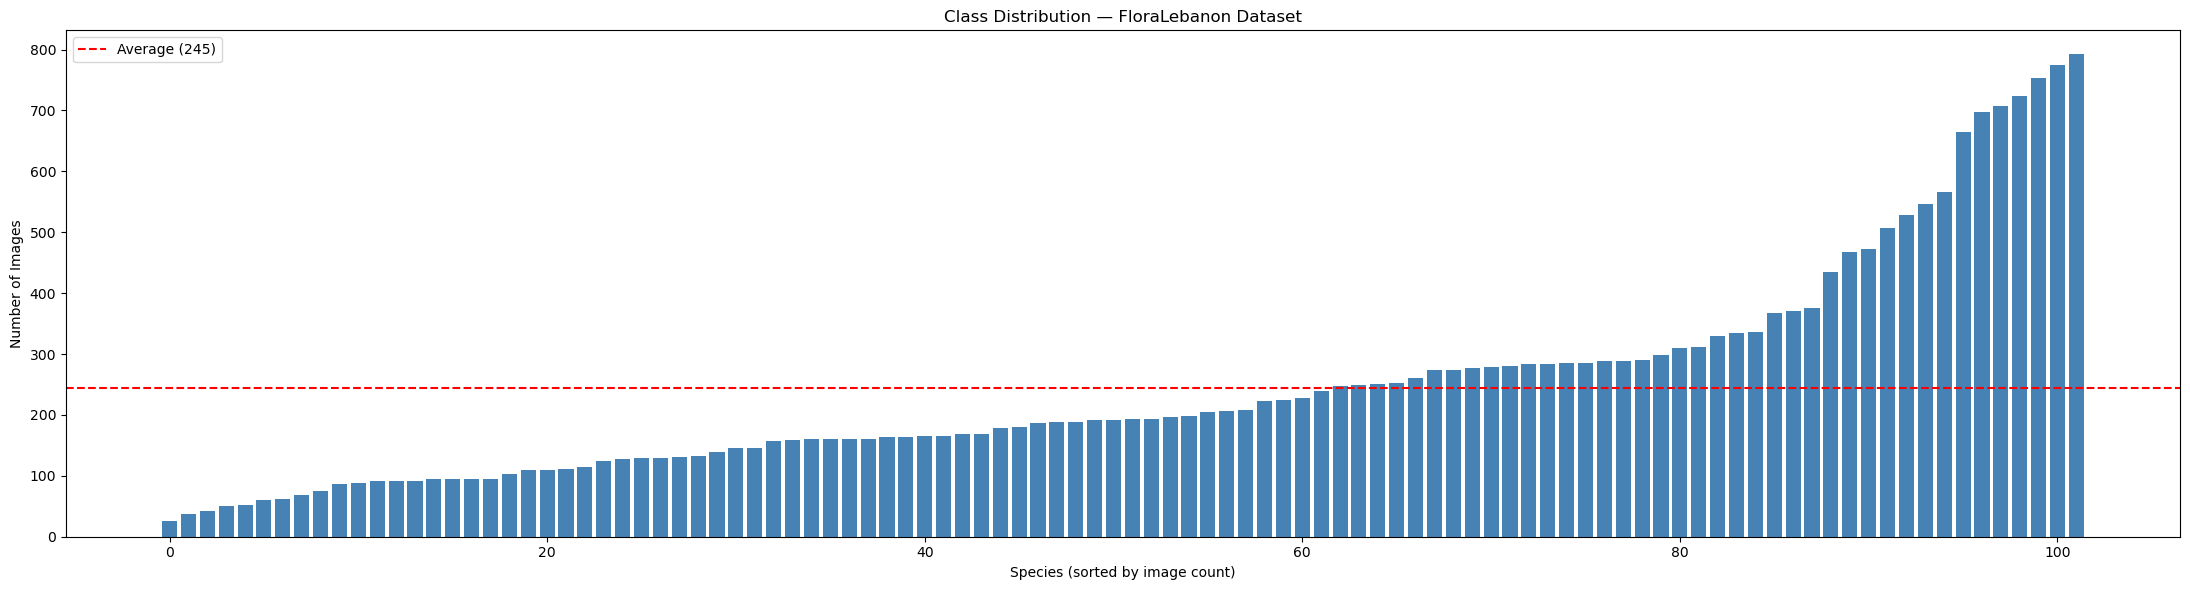

In [5]:
import os
import matplotlib.pyplot as plt

dataset_path = r"E:\Floral_lebanon\FloraLebanon_raw_dataset\FloraLebanon_raw_dataset\SLB-SBR_raw_dataset"

# Count images per species
image_counts = {}
for species in sorted(os.listdir(dataset_path)):
    species_path = os.path.join(dataset_path, species)
    if os.path.isdir(species_path):
        count = len([f for f in os.listdir(species_path) 
                     if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
        image_counts[species] = count

# Sort by count
image_counts = dict(sorted(image_counts.items(), key=lambda x: x[1]))

# Statistics
counts = list(image_counts.values())
print(f"Total species: {len(image_counts)}")
print(f"Total images: {sum(counts)}")
print(f"Min images: {min(counts)}")
print(f"Max images: {max(counts)}")
print(f"Average images: {sum(counts)/len(counts):.1f}")

print("\n--- 10 species with LEAST images ---")
for name, count in list(image_counts.items())[:10]:
    print(f"  {count:4d}  {name}")

print("\n--- 10 species with MOST images ---")
for name, count in list(image_counts.items())[-10:]:
    print(f"  {count:4d}  {name}")

# Plot
plt.figure(figsize=(22, 6))
plt.bar(range(len(image_counts)), list(image_counts.values()), color='steelblue')
plt.xlabel("Species (sorted by image count)")
plt.ylabel("Number of Images")
plt.title("Class Distribution — FloraLebanon Dataset")
plt.axhline(y=sum(counts)/len(counts), color='red', 
            linestyle='--', label=f'Average ({sum(counts)/len(counts):.0f})')
plt.legend()
plt.tight_layout()
plt.savefig("class_distribution.png")
plt.show()

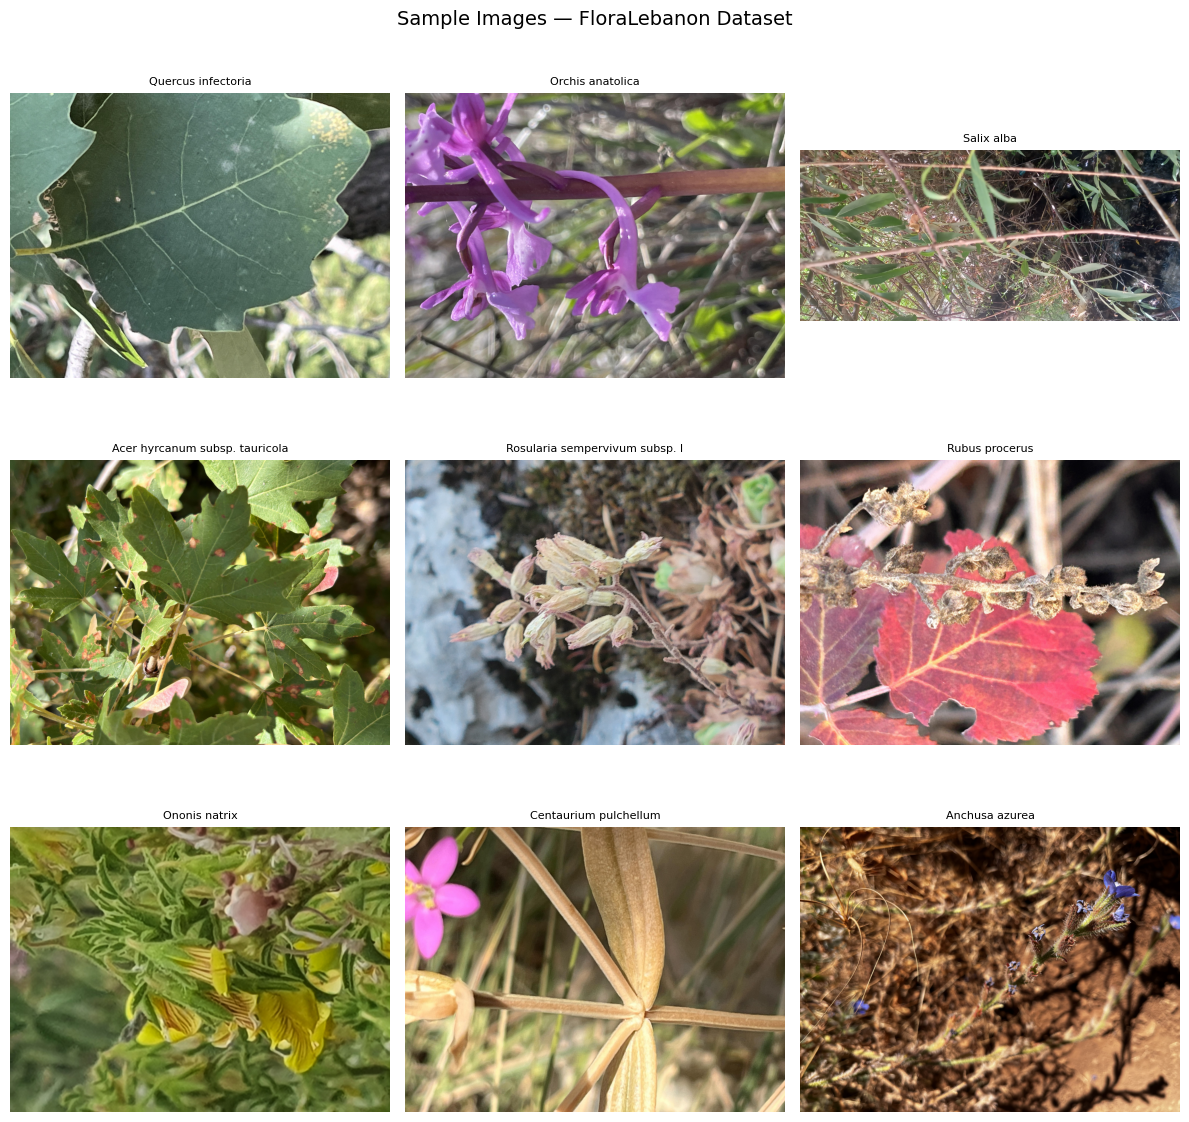

In [1]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import random

dataset_path = r"E:\Floral_lebanon\FloraLebanon_raw_dataset\FloraLebanon_raw_dataset\SLB-SBR_raw_dataset"

# Pick 9 random species and show one image from each
species_list = os.listdir(dataset_path)
selected = random.sample(species_list, 9)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes = axes.flatten()

for i, species in enumerate(selected):
    species_path = os.path.join(dataset_path, species)
    images = [f for f in os.listdir(species_path) 
              if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    
    if images:
        img_path = os.path.join(species_path, random.choice(images))
        img = Image.open(img_path)
        axes[i].imshow(img)
        axes[i].set_title(species[:30], fontsize=8)
        axes[i].axis('off')

plt.suptitle("Sample Images — FloraLebanon Dataset", fontsize=14)
plt.tight_layout()
plt.savefig("sample_images.png")
plt.show()